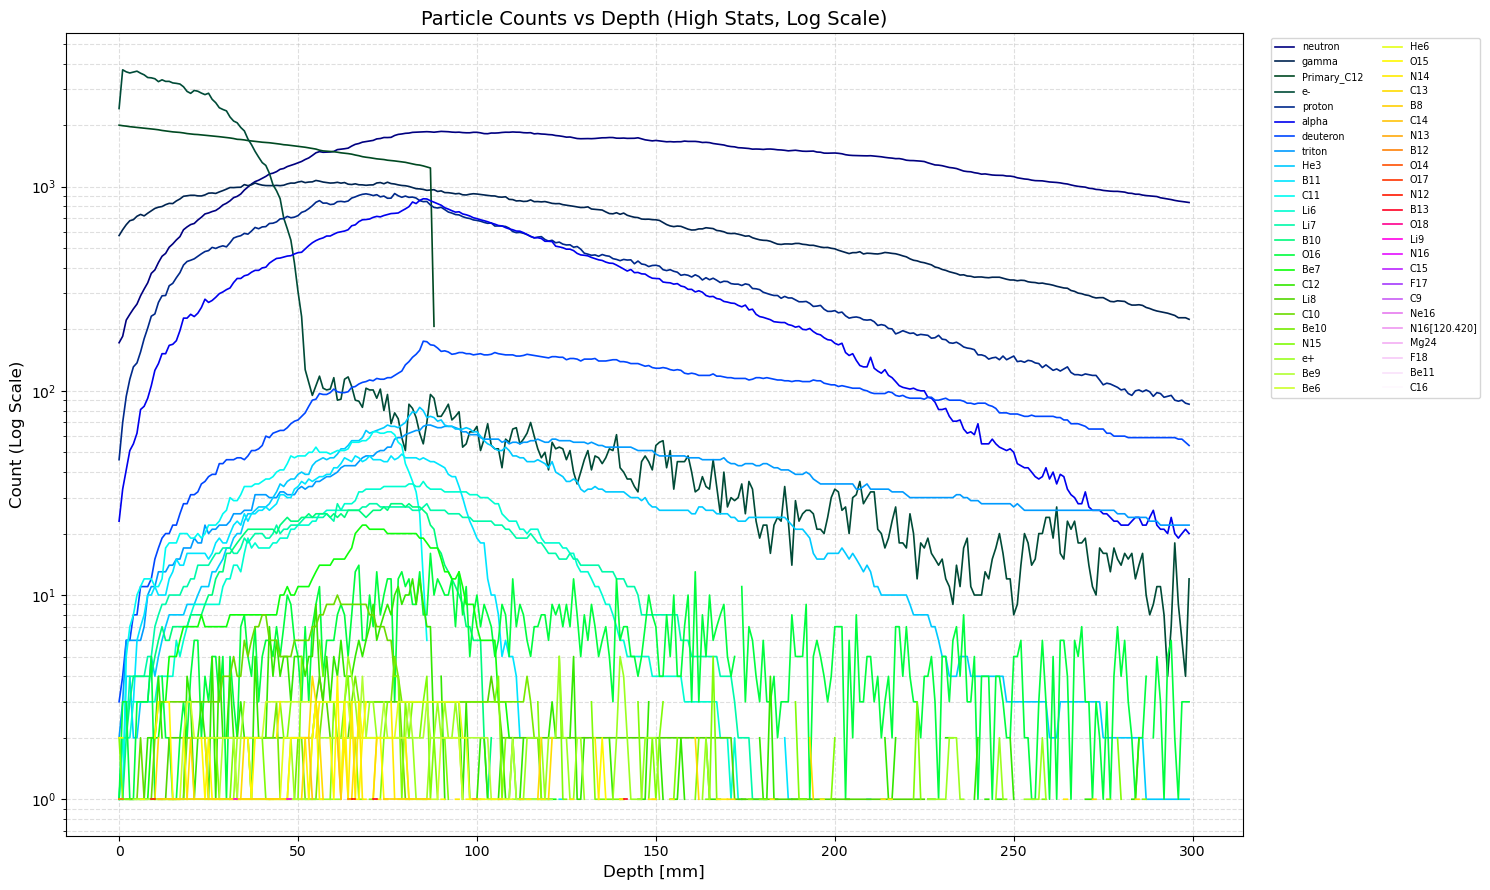

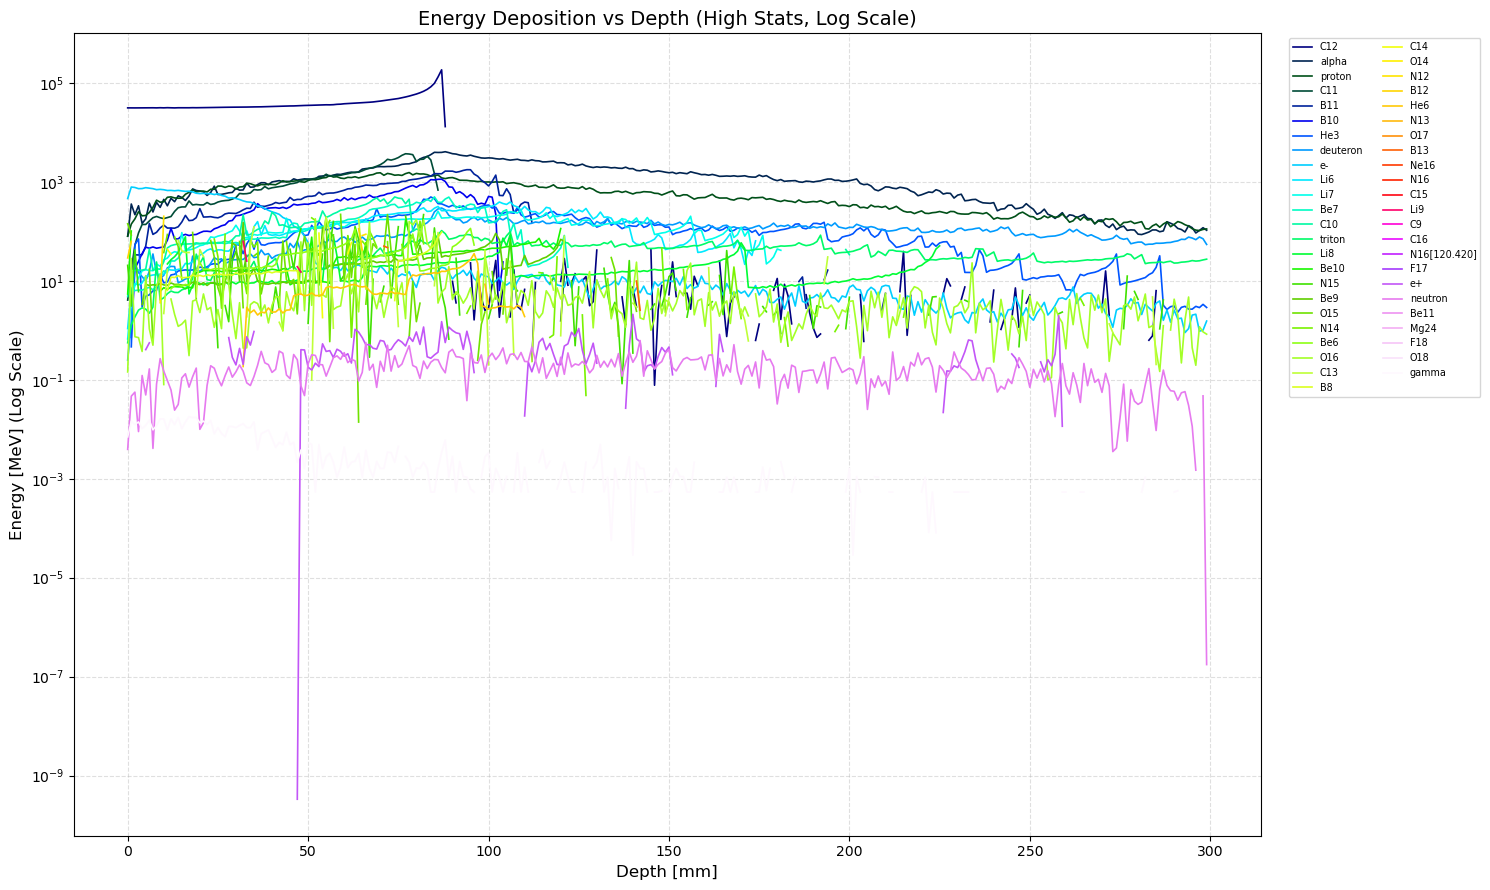

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 高統計データの読み込み
df = pd.read_csv('QGSP_BIC.csv')

def parse_kv(s):
    if not isinstance(s, str) or not s: return {}
    return {k.split(':')[0].strip(): float(k.split(':')[1].strip()) for k in s.split(';') if ':' in k}

# データのパース
energy_dicts = df['energy_details'].apply(parse_kv)
count_dicts = df['secondary_counts'].apply(parse_kv)

# 全ユニーク粒子名の取得
all_particles_energy = sorted(list(set().union(*(d.keys() for d in energy_dicts))))
all_particles_count = sorted(list(set().union(*(d.keys() for d in count_dicts))))

# データフレームの作成
energy_df = pd.DataFrame([{p: d.get(p, 0.0) for p in all_particles_energy} for d in energy_dicts])
count_df = pd.DataFrame([{p: d.get(p, 0.0) for p in all_particles_count} for d in count_dicts])
count_df['Primary_C12'] = df['primaries']

# 深度（mm）
depth = df['copyNo']

def save_and_plot_log(x, data_df, title, ylabel, filename):
    plt.figure(figsize=(15, 9))
    
    # 寄与の合計順にソート（凡例順）
    sorted_cols = data_df.sum().sort_values(ascending=False).index.tolist()
    
    # 推奨されるカラーマップ API
    cmap = plt.get_cmap('gist_ncar')
    colors = cmap(np.linspace(0, 1, len(sorted_cols)))
    
    for i, col in enumerate(sorted_cols):
        y = data_df[col].replace(0, np.nan)
        plt.plot(x, y, label=col, color=colors[i], lw=1.2)
    
    plt.yscale('log')
    plt.xlabel('Depth [mm]', fontsize=12)
    plt.ylabel(ylabel + ' (Log Scale)', fontsize=12)
    plt.title(title, fontsize=14)
    # 凡例を2列にしてグラフ外に配置
    plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize='x-small', ncol=2)
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig(filename) # PNGとして保存
    plt.show()

# プロットと保存の実行
save_and_plot_log(depth, count_df, 'Particle Counts vs Depth (High Stats, Log Scale)', 'Count', 'particle_counts_high_stats.png')
save_and_plot_log(depth, energy_df, 'Energy Deposition vs Depth (High Stats, Log Scale)', 'Energy [MeV]', 'energy_deposition_high_stats.png')